In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os



In [8]:
Bank_churn = pd.read_csv(r"C:\project file\Bank churu project\Bank_Churn.csv")

In [11]:

print(Bank_churn.head())

   CustomerId   Surname  CreditScore Geography  Gender  Age  Tenure  \
0    15634602  Hargrave          619    France  Female   42       2   
1    15647311      Hill          608     Spain  Female   41       1   
2    15619304      Onio          502    France  Female   42       8   
3    15701354      Boni          699    France  Female   39       1   
4    15737888  Mitchell          850     Spain  Female   43       2   

     Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0       0.00              1          1               1        101348.88   
1   83807.86              1          0               1        112542.58   
2  159660.80              3          1               0        113931.57   
3       0.00              2          0               0         93826.63   
4  125510.82              1          1               1         79084.10   

   Exited  
0       1  
1       0  
2       1  
3       0  
4       0  


In [12]:
print (Bank_churn.columns.tolist())

['CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [13]:
print(Bank_churn.dtypes)

CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [15]:
Bank_churn.isnull().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [20]:
print("\nDuplicate row:",Bank_churn.duplicated().sum()
      )


Duplicate row: 0


In [21]:
print(Bank_churn.describe())

         CustomerId   CreditScore           Age        Tenure        Balance  \
count  1.000000e+04  10000.000000  10000.000000  10000.000000   10000.000000   
mean   1.569094e+07    650.528800     38.921800      5.012800   76485.889288   
std    7.193619e+04     96.653299     10.487806      2.892174   62397.405202   
min    1.556570e+07    350.000000     18.000000      0.000000       0.000000   
25%    1.562853e+07    584.000000     32.000000      3.000000       0.000000   
50%    1.569074e+07    652.000000     37.000000      5.000000   97198.540000   
75%    1.575323e+07    718.000000     44.000000      7.000000  127644.240000   
max    1.581569e+07    850.000000     92.000000     10.000000  250898.090000   

       NumOfProducts    HasCrCard  IsActiveMember  EstimatedSalary  \
count   10000.000000  10000.00000    10000.000000     10000.000000   
mean        1.530200      0.70550        0.515100    100090.239881   
std         0.581654      0.45584        0.499797     57510.492818   

In [22]:
print("\nBasic statistics:")


Basic statistics:


In [24]:
Bank_churn_no_dupes = Bank_churn.drop_duplicates()
print("\nRows after removing duplicates:", len(Bank_churn_no_dupes))    


Rows after removing duplicates: 10000


In [29]:
Bank_churn["churn_status"] = Bank_churn["Exited"].map({0: "Stayed", 1: "Churned"})
Bank_churn["Member_status"] = Bank_churn["IsActiveMember"].map({0: "Inactive", 1: "Active"})
Bank_churn["Credit_card"] = Bank_churn["HasCrCard"].map({0: "No", 1: "Yes"})


Bank_churn["Age_group"] = pd.cut(
    Bank_churn["Age"],
    bins=[17, 25, 35, 55, 65, 75, 100],
    labels=["18-25", "26-35", "36-55", "56-65", "66-75", "76-100"]
)


In [30]:
total_customers = len(Bank_churn)

In [32]:
churned_customers = Bank_churn["Exited"].sum()
stayed_customers = total_customers - churned_customers
churn_rate = (churned_customers / total_customers) * 100
retention_rate = (stayed_customers / total_customers) * 100

In [35]:
print("\n")
print("="*40)
print("MAIN CUSTOMER KPIs")




MAIN CUSTOMER KPIs


In [36]:
print("Total customers:", total_customers)
print("Customers who stayed:", stayed_customers)
print("Customers who left:", churned_customers)
print("Churn rate: {:.2f}%".format(churn_rate))
print("Retention rate: {:.2f}%".format(retention_rate))

Total customers: 10000
Customers who stayed: 7963
Customers who left: 2037
Churn rate: 20.37%
Retention rate: 79.63%


In [38]:
country_churn = Bank_churn.groupby("Geography")["Exited"].mean() * 100

print("\nChurn rate by country:")
print(country_churn.sort_values(ascending=False))


Churn rate by country:
Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64


In [39]:
gender_churn = Bank_churn.groupby("Gender")["Exited"].mean() * 100

print("\nChurn rate by gender:")
print(gender_churn.sort_values(ascending=False))




Churn rate by gender:
Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


In [41]:
member_churn = Bank_churn.groupby("Member_status")["Exited"].mean() * 100

print("\nChurn rate by member status:")
print(member_churn.sort_values(ascending=False))



Churn rate by member status:
Member_status
Inactive    26.850897
Active      14.269074
Name: Exited, dtype: float64


In [44]:
age_churn = Bank_churn.groupby(
    "Age_group",
    observed=True
)["Exited"].mean() * 100

print("\nChurn rate by age group:")
print(age_churn.sort_values(ascending=False))


Churn rate by age group:
Age_group
56-65     48.320896
36-55     27.659996
66-75     15.525114
26-35      8.498024
18-25      7.528642
76-100     2.222222
Name: Exited, dtype: float64


In [46]:
product_churn = Bank_churn.groupby("NumOfProducts")["Exited"].mean() * 100

print("\nChurn rate by number of products:")
print(product_churn.sort_values(ascending=False))



Churn rate by number of products:
NumOfProducts
4    100.000000
3     82.706767
1     27.714398
2      7.581699
Name: Exited, dtype: float64


In [47]:
card_churn = Bank_churn.groupby("Credit_card")["Exited"].mean() * 100

print("\nChurn rate by credit card:")
print(card_churn.sort_values(ascending=False))


Churn rate by credit card:
Credit_card
No     20.814941
Yes    20.184266
Name: Exited, dtype: float64


In [48]:
os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)


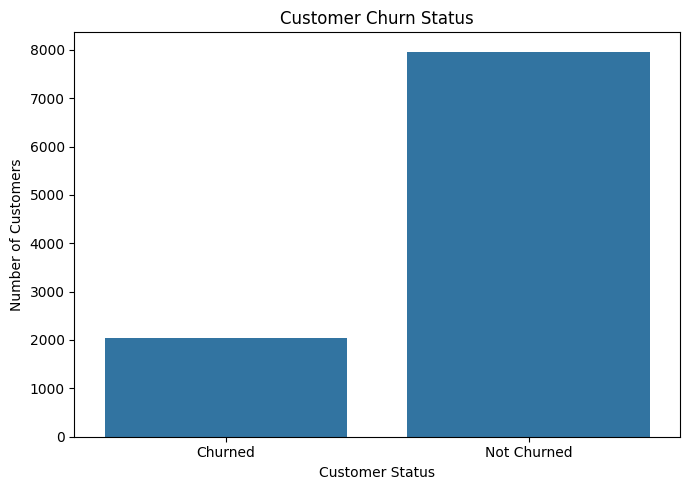

In [50]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=Bank_churn,
    x="status"
)

plt.title("Customer Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "outputs/charts/customer_churn.png",
    dpi=300
)

plt.show()

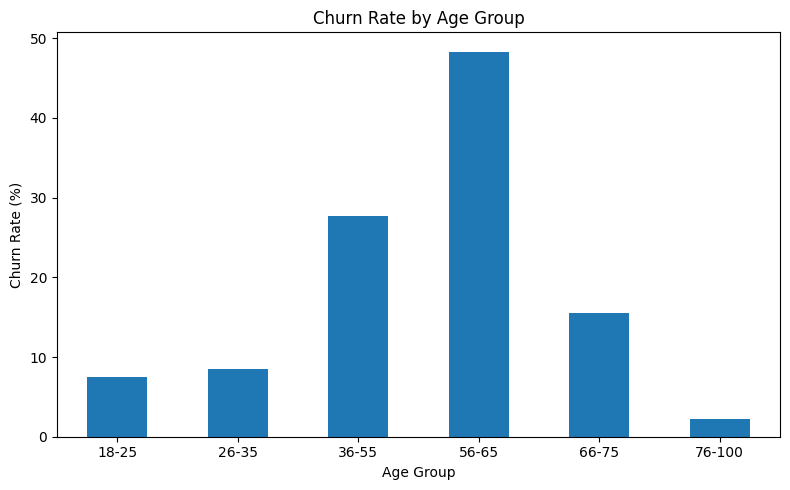

In [51]:
plt.figure(figsize=(8, 5))

age_churn.plot(
    kind="bar"
)

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "outputs/charts/churn_by_age.png",
    dpi=300
)

plt.show()

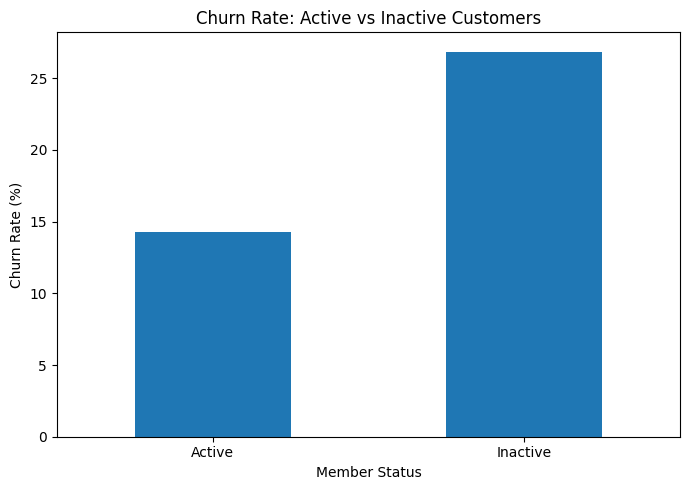

In [52]:
plt.figure(figsize=(7, 5))

member_churn.plot(
    kind="bar"
)

plt.title("Churn Rate: Active vs Inactive Customers")
plt.xlabel("Member Status")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "outputs/charts/churn_by_member_status.png",
    dpi=300
)

plt.show()


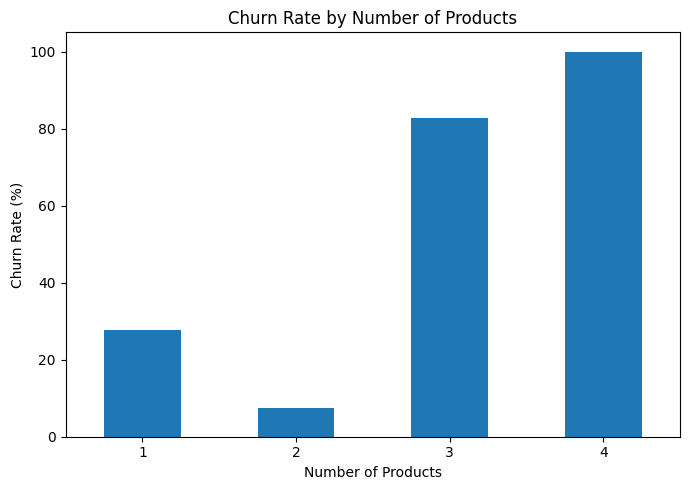

In [53]:
plt.figure(figsize=(7, 5))

product_churn.plot(
    kind="bar"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "outputs/charts/churn_by_products.png",
    dpi=300
)

plt.show()


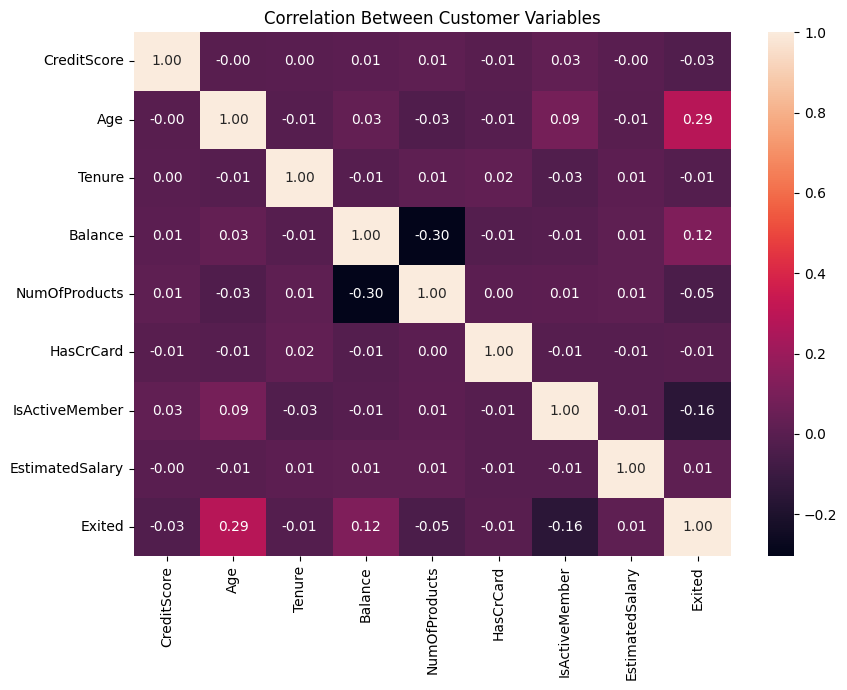

In [54]:
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

correlation = Bank_churn[numeric_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Customer Variables")

plt.tight_layout()

plt.savefig(
    "outputs/charts/correlation.png",
    dpi=300
)

plt.show()


In [55]:
Bank_churn.to_csv(
    "outputs/Bank_Churn_Cleaned.csv",
    index=False
)

In [58]:
with pd.ExcelWriter(
    "outputs/Bank_Churn_Analysis.xlsx",
    engine="openpyxl"
) as writer:

    Bank_churn.to_excel(
        writer,
        sheet_name="Customer Data",
        index=False
    )

    country_churn.reset_index(
        name="Churn Rate (%)"
    ).to_excel(
        writer,
        sheet_name="Country Analysis",
        index=False
    )

    gender_churn.reset_index(
        name="Churn Rate (%)"
    ).to_excel(
        writer,
        sheet_name="Gender Analysis",
        index=False
    )

    member_churn.reset_index(
        name="Churn Rate (%)"
    ).to_excel(
        writer,
        sheet_name="Member Analysis",
        index=False
    )

    age_churn.reset_index(
        name="Churn Rate (%)"
    ).to_excel(
        writer,
        sheet_name="Age Analysis",
        index=False
    )

    product_churn.reset_index(
        name="Churn Rate (%)"
    ).to_excel(
        writer,
        sheet_name="Product Analysis",
        index=False
    )


In [59]:
highest_country = country_churn.idxmax()
highest_country_rate = country_churn.max()

highest_age = age_churn.idxmax()
highest_age_rate = age_churn.max()

highest_product = product_churn.idxmax()
highest_product_rate = product_churn.max()


print("\n")
print("=" * 40)
print("BUSINESS SUMMARY")
print("=" * 40)

print(
    "The overall customer churn rate is "
    "{:.2f}%.".format(churn_rate)
)

print(
    "The country with the highest churn is "
    "{} with {:.2f}%.".format(
        highest_country,
        highest_country_rate
    )
)

print(
    "The age group with the highest churn is "
    "{} with {:.2f}%.".format(
        highest_age,
        highest_age_rate
    )
)

print(
    "The highest churn by number of products is "
    "{} products with {:.2f}%.".format(
        highest_product,
        highest_product_rate
    )
)

print("\nMain recommendations:")

print("1. Focus on customers who are not active.")

print("2. Investigate the high churn rate in Germany.")

print("3. Create retention campaigns for high-risk age groups.")

print("4. Check why customers with multiple products are leaving.")

print("5. Use Power BI to monitor customer churn regularly.")

print("\nProject completed successfully.")



BUSINESS SUMMARY
The overall customer churn rate is 20.37%.
The country with the highest churn is Germany with 32.44%.
The age group with the highest churn is 56-65 with 48.32%.
The highest churn by number of products is 4 products with 100.00%.

Main recommendations:
1. Focus on customers who are not active.
2. Investigate the high churn rate in Germany.
3. Create retention campaigns for high-risk age groups.
4. Check why customers with multiple products are leaving.
5. Use Power BI to monitor customer churn regularly.

Project completed successfully.
